# Load confirmation -- loader verdict vs ground truth

Driver for `analyze_load_confirmation.py`. Run in the **working BLAS** Python
env (not artiq7_claude).

Scores the deterministic loader as a classifier against the confirmation image:
per MOT time it reports loader **success %**, **CONFIRMED %** (real atom), and the
**PHANTOM %** (declared loads with no atom -- the ones that waste parity/rate cycles),
plus a recommended loader threshold. Needs a run from the confirmation version of
the experiment (has `det_confirmed`).

In [4]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
ANALYSIS_DIR = Path("C:/Networking Experiment/Artiq7_TEST_NEW/useful_codes/repository/analysis")
for p in (str(ANALYSIS_DIR.parent), str(ANALYSIS_DIR)):
    if p not in sys.path: sys.path.insert(0, p)
from analyze_load_confirmation import (
    find_runs, load_run, per_mot, recommend_threshold,
    print_report, plot_report, analyze, _rid_of, RESULTS_DIR)
%matplotlib inline
print('Setup complete'); print('Results dir:', RESULTS_DIR)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Setup complete
Results dir: C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\results


## 1. Latest run

File: 000003608-AtomLoadDeterministicTest.h5   RID=3608   shots=1600
  loader threshold: 2000 counts/s (= 16 summed counts/gate);  atom confirm vs image.

   MOT ms     N   succ %   CONF %  PHANTOM %  fidelity  miss %
       20   200    100.0     93.0        7.0      93.0     0.0
       40   200    100.0     92.0        8.0      92.0     0.0
       60   200    100.0     76.5       23.5      76.5     0.0
       80   200    100.0     66.5       33.5      66.5     0.0
      100   200    100.0     42.5       57.5      42.5     0.0
      120   200    100.0     31.5       68.5      31.5     0.0
      140   200    100.0     28.5       71.5      28.5     0.0
      160   200    100.0     40.0       60.0      40.0     0.0

  Clean-detection ceiling: MOT <= 40 ms keeps phantoms <=10% (at 40 ms: 8.0% phantom).
  Above that the loader false-triggers on the bright MOT (phantom up to 72%).

  Loader counts: real atoms median 29, phantoms median 19 (current cut 16).
  RECOMMEND threshold -> 4125 count

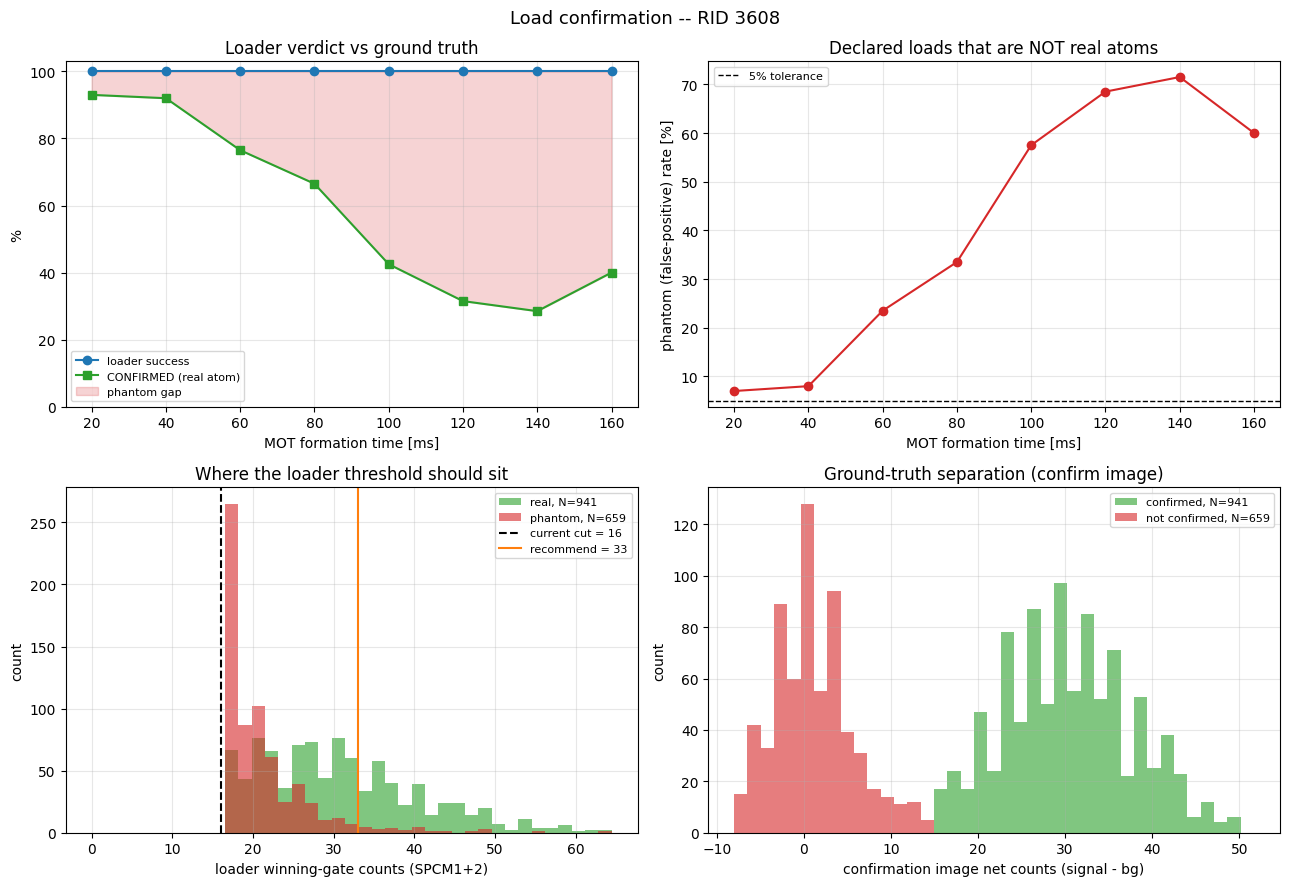

In [5]:
res = analyze(find_runs()[-1])

## 2. A specific RID
Set `RID` to your confirmation scan run.

File: 000003608-AtomLoadDeterministicTest.h5   RID=3608   shots=1600
  loader threshold: 2000 counts/s (= 16 summed counts/gate);  atom confirm vs image.

   MOT ms     N   succ %   CONF %  PHANTOM %  fidelity  miss %
       20   200    100.0     93.0        7.0      93.0     0.0
       40   200    100.0     92.0        8.0      92.0     0.0
       60   200    100.0     76.5       23.5      76.5     0.0
       80   200    100.0     66.5       33.5      66.5     0.0
      100   200    100.0     42.5       57.5      42.5     0.0
      120   200    100.0     31.5       68.5      31.5     0.0
      140   200    100.0     28.5       71.5      28.5     0.0
      160   200    100.0     40.0       60.0      40.0     0.0

  Clean-detection ceiling: MOT <= 40 ms keeps phantoms <=10% (at 40 ms: 8.0% phantom).
  Above that the loader false-triggers on the bright MOT (phantom up to 72%).

  Loader counts: real atoms median 29, phantoms median 19 (current cut 16).
  RECOMMEND threshold -> 4125 count

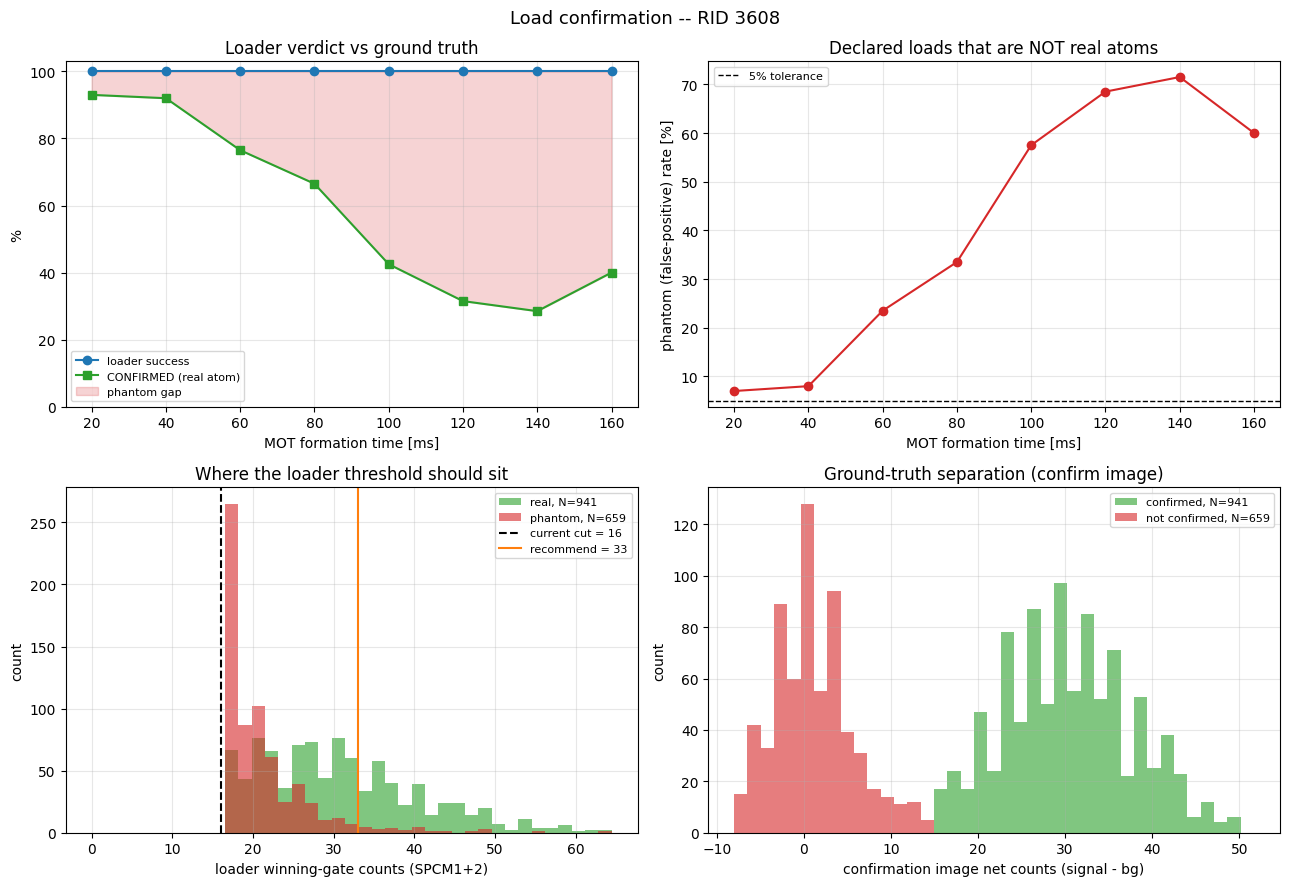

In [6]:
RID = 3608   # <-- set to your run
path = [f for f in find_runs() if _rid_of(f) == RID][-1]
res = analyze(path)

## 3. Just the threshold recommendation
`max_phantom` is the phantom tolerance for the suggested loader threshold
(0.05 = reject >=95% of phantoms). Lower it to be stricter.

File: 000003608-AtomLoadDeterministicTest.h5   RID=3608   shots=1600
  loader threshold: 2000 counts/s (= 16 summed counts/gate);  atom confirm vs image.

   MOT ms     N   succ %   CONF %  PHANTOM %  fidelity  miss %
       20   200    100.0     93.0        7.0      93.0     0.0
       40   200    100.0     92.0        8.0      92.0     0.0
       60   200    100.0     76.5       23.5      76.5     0.0
       80   200    100.0     66.5       33.5      66.5     0.0
      100   200    100.0     42.5       57.5      42.5     0.0
      120   200    100.0     31.5       68.5      31.5     0.0
      140   200    100.0     28.5       71.5      28.5     0.0
      160   200    100.0     40.0       60.0      40.0     0.0

  Clean-detection ceiling: MOT <= 40 ms keeps phantoms <=10% (at 40 ms: 8.0% phantom).
  Above that the loader false-triggers on the bright MOT (phantom up to 72%).

  Loader counts: real atoms median 29, phantoms median 19 (current cut 16).
  RECOMMEND threshold -> 5000 count

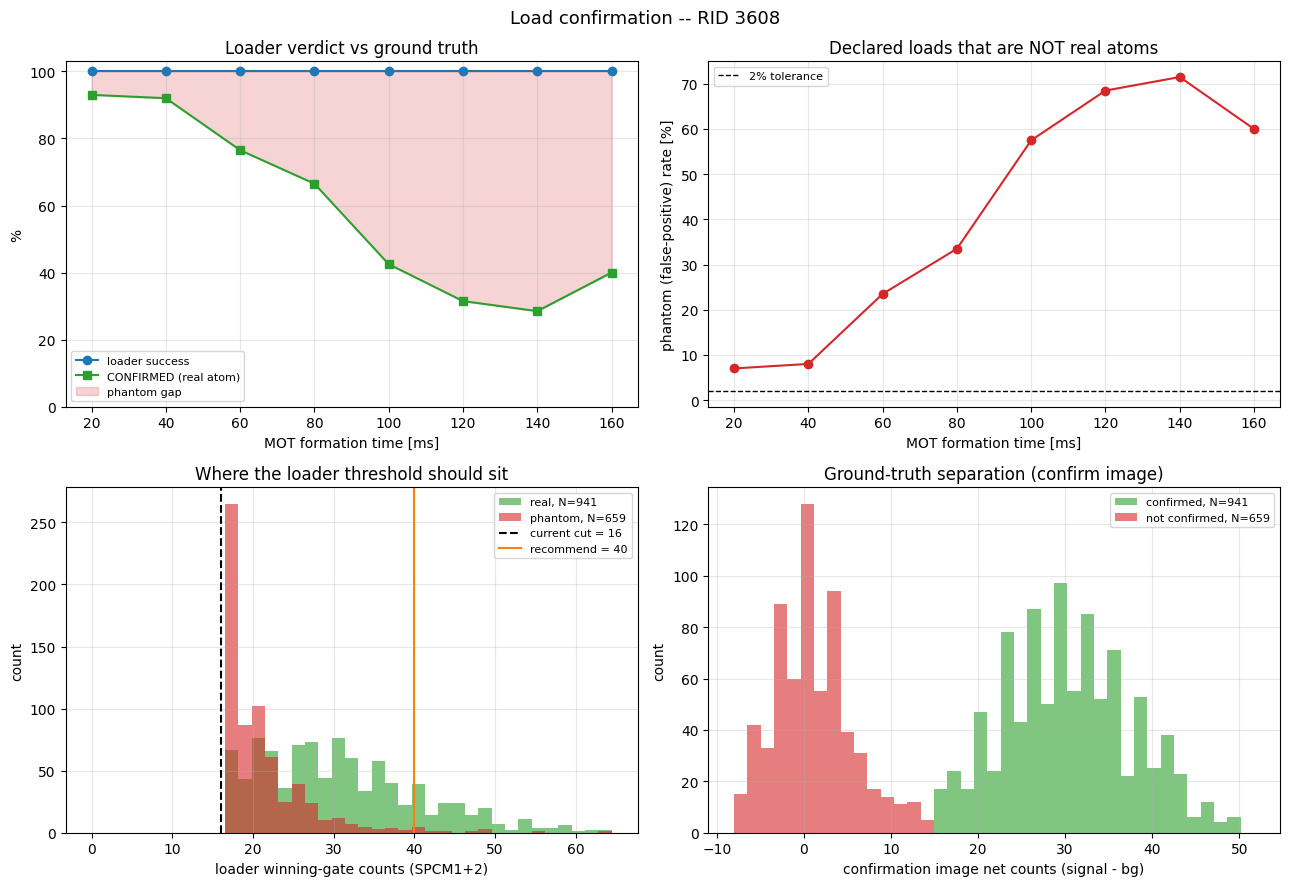

{'ok': True,
 'cur_sum': 16.0,
 'cur_cps': 2000.0,
 'rec_sum': 40,
 'rec_cps': 5000.0,
 'real_kept': 0.18597236981934112,
 'phantom_kept': 0.019726858877086494,
 'n_real': 941,
 'n_phantom': 659,
 'real_med': 29.0,
 'phantom_med': 19.0}

In [7]:
res = analyze(path, max_phantom=0.02)
res['rec']   # dict: recommended counts/s, % real kept, % phantoms rejected